In [1]:
# Compare models trained with batch sizes 32 and 64 on the same test images.
import csv
import json
from pathlib import Path
import numpy as np
import tensorflow as tf
from IPython.display import Markdown, display

lab_candidates = [Path.cwd(), Path.cwd() / "lab_vgg"]
lab_dir = next(
    (path.resolve() for path in lab_candidates if (path / "binary_classification_train.ipynb").is_file()),
    None,
)
if lab_dir is None:
    raise FileNotFoundError("Start Jupyter from the repository root or lab_vgg.")

batch_sizes = [32, 64]  # Training batch sizes associated with the saved weights.
class_names_file = lab_dir / "pet_expression_class_names.json"
if not class_names_file.is_file():
    raise FileNotFoundError("Run binary_classification_train.ipynb first to save the class labels.")
class_names = json.loads(class_names_file.read_text(encoding="utf-8"))
num_classes = len(class_names)
print("Class labels:", dict(enumerate(class_names)))


Class labels: {0: 'Angry', 1: 'Other', 2: 'Sad', 3: 'happy'}


In [2]:
# Identical VGG19 architecture is defined inside the training notebook.
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.optimizers import Adam


IMAGE_SIZE = (256, 256)


def build_vgg19_model(num_classes, weights="imagenet"):
    """Accept RGB pixels in [0, 255]; use weights=None before loading saved weights."""
    if num_classes < 2:
        raise ValueError("At least two expression classes are required.")

    base_model = VGG19(
        include_top=False,
        weights=weights,
        input_shape=(*IMAGE_SIZE, 3),
    )
    base_model.trainable = False

    model = models.Sequential(
        [
            layers.Input(shape=(*IMAGE_SIZE, 3)),
            layers.Lambda(preprocess_input, name="vgg19_preprocessing"),
            base_model,
            layers.GlobalAveragePooling2D(),
            layers.Dense(128, activation="relu"),
            layers.Dropout(0.5),
            layers.Dense(num_classes, activation="softmax"),
        ],
        name="pet_expression_vgg19",
    )
    model.compile(
        optimizer=Adam(learning_rate=0.0001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


In [3]:
# Check that both independent training runs saved their weights.
weights_files = {
    batch_size: lab_dir / f"TL_VGG19_pet_expression_batch{batch_size}.weights.h5"
    for batch_size in batch_sizes
}
for batch_size, weights_file in weights_files.items():
    if not weights_file.is_file():
        raise FileNotFoundError(
            f"Missing {weights_file.name}. Run training for batch size {batch_size} first."
        )
    print(f"Batch {batch_size}: {weights_file.name}")


Batch 32: TL_VGG19_pet_expression_batch32.weights.h5
Batch 64: TL_VGG19_pet_expression_batch64.weights.h5


In [4]:
# Load the held-out split once and keep sample order fixed for both models.
test_dir = lab_dir / "preprocess_pet_facial_expression_dataset" / "test"
if not test_dir.is_dir():
    raise FileNotFoundError("Test split missing. Run the training preprocessing cells first.")
evaluation_batch_size = 32  # Same inference batching for both training experiments.
test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="int",
    class_names=class_names,
    batch_size=evaluation_batch_size,
    image_size=IMAGE_SIZE,
    shuffle=False,
)
test_ds = test_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
true_labels = np.concatenate([labels.numpy() for _, labels in test_ds])
print(f"Evaluating both models on {len(true_labels)} identical held-out images.")


Found 152 files belonging to 4 classes.
Evaluating both models on 152 identical held-out images.


In [5]:
# Load each model separately and measure held-out classification performance.
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    log_loss, precision_recall_fscore_support,
)

test_results = []
predictions_by_batch = {}
confusion_matrices = {}
for batch_size in batch_sizes:
    tf.keras.backend.clear_session()
    # Saved weights include VGG19, so testing needs no ImageNet download.
    model = build_vgg19_model(num_classes, weights=None)
    model.load_weights(str(weights_files[batch_size]))
    probabilities = model.predict(test_ds)
    predicted_labels = np.argmax(probabilities, axis=1)
    predictions_by_batch[batch_size] = predicted_labels
    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels, predicted_labels, labels=range(num_classes),
        average="macro", zero_division=0,
    )
    test_results.append({
        "training_batch_size": batch_size,
        "test_images": len(true_labels),
        "test_loss": float(log_loss(true_labels, probabilities, labels=range(num_classes))),
        "accuracy": float(accuracy_score(true_labels, predicted_labels)),
        "macro_precision": float(precision),
        "macro_recall": float(recall),
        "macro_f1": float(f1),
    })
    confusion_matrices[batch_size] = confusion_matrix(
        true_labels, predicted_labels, labels=range(num_classes)
    )
    print(f"\nVGG19 trained with batch size {batch_size}")
    print(classification_report(
        true_labels, predicted_labels, labels=range(num_classes),
        target_names=class_names, digits=4, zero_division=0,
    ))
    del model

comparison_file = lab_dir / "VGG19_batch_test_comparison.csv"
with comparison_file.open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(test_results[0]))
    writer.writeheader()
    writer.writerows(test_results)

rows = [
    "| Training batch | Test loss | Accuracy | Macro precision | Macro recall | Macro F1 |",
    "|---|---|---|---|---|---|",
]
for result in test_results:
    rows.append(
        f"| {result['training_batch_size']} | {result['test_loss']:.4f} | "
        f"{result['accuracy']:.4f} | {result['macro_precision']:.4f} | "
        f"{result['macro_recall']:.4f} | {result['macro_f1']:.4f} |"
    )
display(Markdown("\n".join(rows)))
print(f"Saved: {comparison_file}")
print("Macro metrics give each expression class equal weight.")


c:\Users\Pc\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step

VGG19 trained with batch size 32
              precision    recall  f1-score   support

       Angry     0.4667    0.5526    0.5060        38
       Other     0.4545    0.3947    0.4225        38
         Sad     0.4516    0.3684    0.4058        38
       happy     0.6047    0.6842    0.6420        38

    accuracy                         0.5000       152
   macro avg     0.4944    0.5000    0.4941       152
weighted avg     0.4944    0.5000    0.4941       152



c:\Users\Pc\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step

VGG19 trained with batch size 64
              precision    recall  f1-score   support

       Angry     0.4130    0.5000    0.4524        38
       Other     0.3125    0.2632    0.2857        38
         Sad     0.3438    0.2895    0.3143        38
       happy     0.5476    0.6053    0.5750        38

    accuracy                         0.4145       152
   macro avg     0.4042    0.4145    0.4068       152
weighted avg     0.4042    0.4145    0.4068       152



| Training batch | Test loss | Accuracy | Macro precision | Macro recall | Macro F1 |
|---|---|---|---|---|---|
| 32 | 1.6592 | 0.5000 | 0.4944 | 0.5000 | 0.4941 |
| 64 | 2.2067 | 0.4145 | 0.4042 | 0.4145 | 0.4068 |

Saved: C:\Users\Pc\Documents\GitHub\AI_class\lab_vgg\VGG19_batch_test_comparison.csv
Macro metrics give each expression class equal weight.


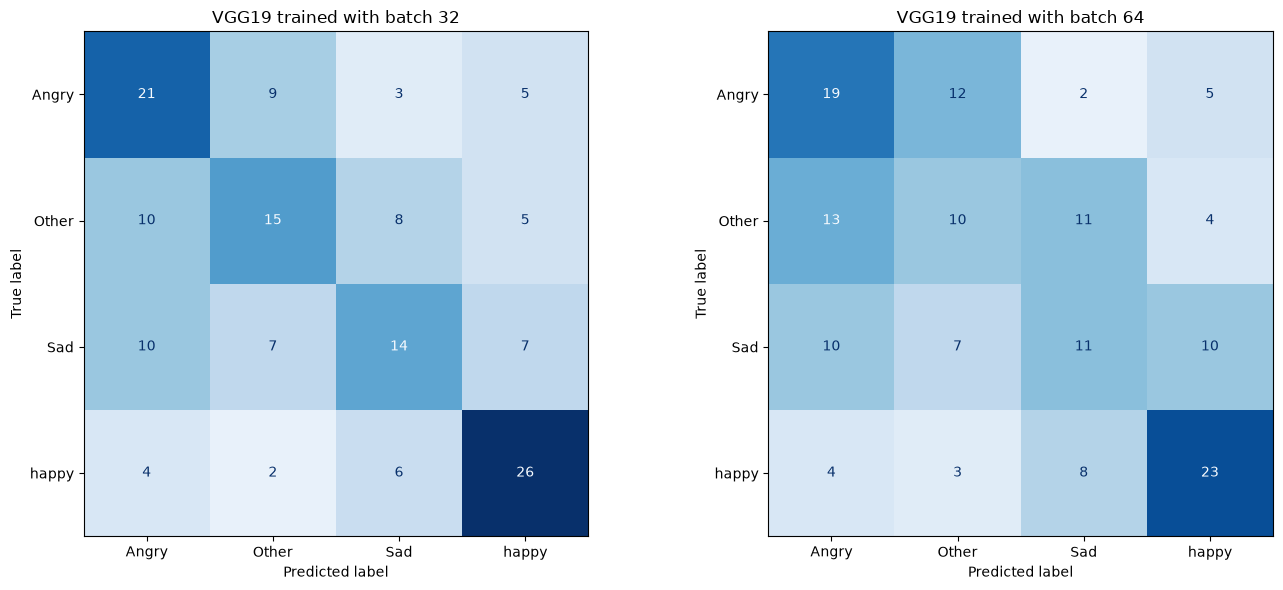

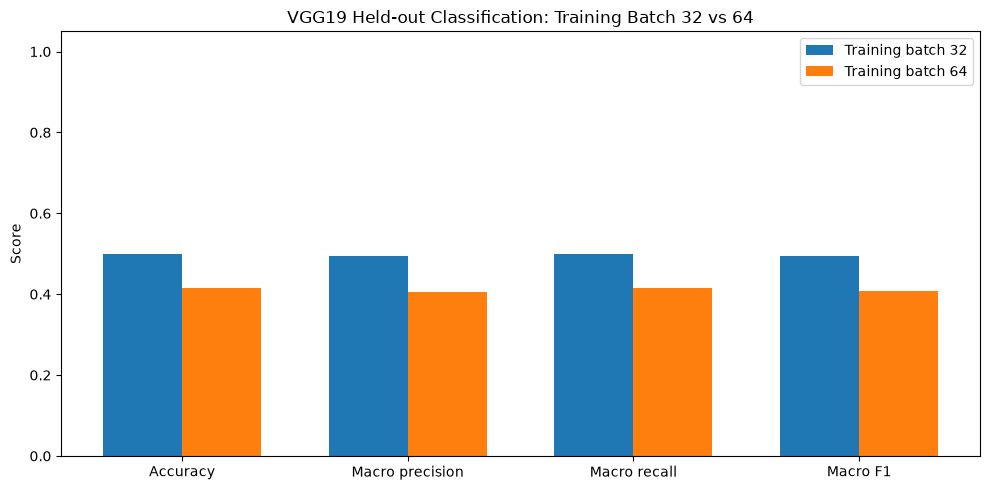

accuracy: batch 32 is higher by 8.55 percentage points.
macro_f1: batch 32 is higher by 8.72 percentage points.


In [6]:
# Show confusion matrices using identical labels and color scales.
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, len(batch_sizes), figsize=(14, 6), squeeze=False)
max_count = max(matrix.max() for matrix in confusion_matrices.values())
for ax, batch_size in zip(axes[0], batch_sizes):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrices[batch_size], display_labels=class_names
    )
    disp.plot(
        ax=ax, cmap=plt.cm.Blues, values_format="d", colorbar=False,
        im_kw={"vmin": 0, "vmax": max_count},
    )
    ax.set_title(f"VGG19 trained with batch {batch_size}")
plt.tight_layout()
plt.show()

# Compare aggregate classification metrics side by side.
metric_names = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]
x = np.arange(len(metric_names))
fig, ax = plt.subplots(figsize=(10, 5))
bar_width = 0.35
for index, result in enumerate(test_results):
    offset = (index - (len(test_results) - 1) / 2) * bar_width
    ax.bar(
        x + offset, [result[metric] for metric in metric_names], bar_width,
        label=f"Training batch {result['training_batch_size']}",
    )
ax.set_xticks(x, ["Accuracy", "Macro precision", "Macro recall", "Macro F1"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("VGG19 Held-out Classification: Training Batch 32 vs 64")
ax.legend()
plt.tight_layout()
plt.show()

# Report observed differences; a single seeded run is not a significance test.
by_batch = {result["training_batch_size"]: result for result in test_results}
for metric in ["accuracy", "macro_f1"]:
    delta = by_batch[64][metric] - by_batch[32][metric]
    if np.isclose(delta, 0):
        print(f"{metric}: tie between batch sizes 32 and 64.")
    else:
        better_batch = 64 if delta > 0 else 32
        print(f"{metric}: batch {better_batch} is higher by {abs(delta) * 100:.2f} percentage points.")


## EfficientNetB0 versus VGG19: held-out classification comparison

Run after both EfficientNetB0 training runs finish. If the kernel was restarted, run the original VGG19 model-definition cell (the second code cell), then run this appended section; previous evaluation cells do not need to be repeated. This section restores all four models, uses the same ordered test images with evaluation batch size 32, and exports classification metrics, reports, confusion matrices, and comparison plots. It does not train models or download ImageNet weights.


In [7]:
import csv
import json
import time
from pathlib import Path
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# This section can use previously saved VGG19 artifacts after a kernel restart.
en_lab_dir = next(
    (p.resolve() for p in [Path.cwd(), Path.cwd() / "lab_vgg"]
     if (p / "binary_classification_train.ipynb").is_file()),
    None,
)
if en_lab_dir is None:
    raise FileNotFoundError("Start Jupyter from the repository root or lab_vgg.")
en_labels_file = en_lab_dir / "pet_expression_class_names.json"
if not en_labels_file.is_file():
    raise FileNotFoundError("Run the VGG19 training section first to save class labels and splits.")
en_class_names = json.loads(en_labels_file.read_text(encoding="utf-8"))
en_num_classes = len(en_class_names)
en_batch_sizes = [32, 64]
EN_IMAGE_SIZE = (256, 256)
en_split_dir = en_lab_dir / "preprocess_pet_facial_expression_dataset"

if "build_vgg19_model" not in globals():
    raise RuntimeError("Run the original VGG19 architecture cell (second code cell) first.")
en_model_weights = {
    (name, batch): en_lab_dir / f"TL_{name}_pet_expression_batch{batch}.weights.h5"
    for name in ["VGG19", "EfficientNetB0"] for batch in en_batch_sizes
}
for en_path in en_model_weights.values():
    if not en_path.is_file():
        raise FileNotFoundError(f"Missing {en_path.name}; finish its training run first.")

# Check the saved EfficientNet class order before interpreting its predictions.
en_model_configs = {}
for en_batch in en_batch_sizes:
    en_metadata_file = en_lab_dir / f"EfficientNetB0_batch{en_batch}_history.json"
    if not en_metadata_file.is_file():
        raise FileNotFoundError(f"Missing {en_metadata_file.name}; finish EfficientNet training first.")
    en_metadata = json.loads(en_metadata_file.read_text(encoding="utf-8"))
    en_model_configs[en_batch] = en_metadata["model_json"]
    if en_metadata["class_names"] != en_class_names:
        raise ValueError("Saved EfficientNetB0 class order differs from the current labels.")
    if en_metadata["image_size"] != list(EN_IMAGE_SIZE):
        raise ValueError("Saved EfficientNetB0 image size differs from evaluation image size.")

en_test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    en_split_dir / "test", labels="inferred", label_mode="int",
    class_names=en_class_names, batch_size=32, image_size=EN_IMAGE_SIZE, shuffle=False,
).prefetch(tf.data.AUTOTUNE)
en_true_labels = np.concatenate([labels.numpy() for _, labels in en_test_ds])
print(f"Comparing all four models on {len(en_true_labels)} identical test images.")


Found 152 files belonging to 4 classes.
Comparing all four models on 152 identical test images.


In [8]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.optimizers import Adam


def build_efficientnetb0_model(num_classes, weights="imagenet", learning_rate=0.0001):
    """Accept RGB pixels in [0, 255]; EfficientNet includes input scaling."""
    if num_classes < 2:
        raise ValueError("At least two expression classes are required.")
    backbone = EfficientNetB0(
        include_top=False, weights=weights, input_shape=(*EN_IMAGE_SIZE, 3)
    )
    backbone.trainable = False
    inputs = layers.Input(shape=(*EN_IMAGE_SIZE, 3))
    # Keep backbone BatchNormalization and stochastic layers in inference mode.
    features = backbone(inputs, training=False)
    features = layers.GlobalAveragePooling2D()(features)
    features = layers.Dense(128, activation="relu")(features)
    features = layers.Dropout(0.5)(features)
    outputs = layers.Dense(num_classes, activation="softmax")(features)
    model = models.Model(inputs, outputs, name="pet_expression_efficientnetb0")
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"],
    )
    return model


In [9]:
# Evaluate one model at a time to limit memory use; never call fit here.
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    log_loss, precision_recall_fscore_support, ConfusionMatrixDisplay,
)

en_test_results = []
en_confusion_matrices = {}
en_class_reports = {}
for en_name in ["VGG19", "EfficientNetB0"]:
    for en_batch in en_batch_sizes:
        tf.keras.backend.clear_session()
        if en_name == "VGG19":
            en_model = build_vgg19_model(en_num_classes, weights=None)
        else:
            # Restore the exact training architecture: Keras adds an extra scaling
            # layer when EfficientNet is built with ImageNet weights.
            en_model = tf.keras.models.model_from_json(en_model_configs[en_batch])
        en_model.load_weights(str(en_model_weights[(en_name, en_batch)]))
        en_probabilities = en_model.predict(en_test_ds)
        en_predicted = np.argmax(en_probabilities, axis=1)
        en_precision, en_recall, en_f1, _ = precision_recall_fscore_support(
            en_true_labels, en_predicted, labels=range(en_num_classes),
            average="macro", zero_division=0,
        )
        en_test_results.append({
            "model": en_name, "training_batch_size": en_batch,
            "test_images": len(en_true_labels),
            "test_loss": float(log_loss(
                en_true_labels, en_probabilities, labels=range(en_num_classes)
            )),
            "accuracy": float(accuracy_score(en_true_labels, en_predicted)),
            "macro_precision": float(en_precision),
            "macro_recall": float(en_recall), "macro_f1": float(en_f1),
        })
        en_confusion_matrices[(en_name, en_batch)] = confusion_matrix(
            en_true_labels, en_predicted, labels=range(en_num_classes)
        )
        en_class_reports[f"{en_name}_batch{en_batch}"] = classification_report(
            en_true_labels, en_predicted, labels=range(en_num_classes),
            target_names=en_class_names, output_dict=True, zero_division=0,
        )
        print(f"\n{en_name}, training batch {en_batch}")
        print(classification_report(
            en_true_labels, en_predicted, labels=range(en_num_classes),
            target_names=en_class_names, digits=4, zero_division=0,
        ))
        del en_model

en_test_csv = en_lab_dir / "VGG19_vs_EfficientNetB0_test_comparison.csv"
with en_test_csv.open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(en_test_results[0]))
    writer.writeheader()
    writer.writerows(en_test_results)
en_report_path = en_lab_dir / "VGG19_vs_EfficientNetB0_classification_reports.json"
en_report_path.write_text(json.dumps(en_class_reports, indent=2), encoding="utf-8")

en_test_table = [
    "| Model | Training batch | Test loss | Accuracy | Macro precision | Macro recall | Macro F1 |",
    "|---|---|---|---|---|---|---|",
]
for row in en_test_results:
    en_test_table.append(
        f"| {row['model']} | {row['training_batch_size']} | {row['test_loss']:.4f} | "
        f"{row['accuracy']:.4f} | {row['macro_precision']:.4f} | "
        f"{row['macro_recall']:.4f} | {row['macro_f1']:.4f} |"
    )
display(Markdown("\n".join(en_test_table)))
print(f"Saved metrics: {en_test_csv}")
print(f"Saved class reports: {en_report_path}")


c:\Users\Pc\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


4/5 ━━━━━━━━━━━━━━━━━━━━ 1s 2s/stepWARNING:tensorflow:5 out of the last 11 calls to <function Trainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x000001F300ACFAB0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step

VGG19, training batch 32
              precision    recall  f1-score   support

       Angry     0.4667    0.5526    0.5060        38
       Other     0.4545    0.3947    0.4225        38
         Sad     0.4516

c:\Users\Pc\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step

VGG19, training batch 64
              precision    recall  f1-score   support

       Angry     0.4130    0.5000    0.4524        38
       Other     0.3125    0.2632    0.2857        38
         Sad     0.3438    0.2895    0.3143        38
       happy     0.5476    0.6053    0.5750        38

    accuracy                         0.4145       152
   macro avg     0.4042    0.4145    0.4068       152
weighted avg     0.4042    0.4145    0.4068       152

5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 422ms/step

EfficientNetB0, training batch 32
              precision    recall  f1-score   support

       Angry     0.7222    0.6842    0.7027        38
       Other     0.7073    0.7632    0.7342        38
         Sad     0.8438    0.7105    0.7714        38
       happy     0.7209    0.8158    0.7654        38

    accuracy                         0.7434       152
   macro avg     0.7486    0.7434    0.7434       152
weighted avg     0.7486    0.7434    0.7434      

| Model | Training batch | Test loss | Accuracy | Macro precision | Macro recall | Macro F1 |
|---|---|---|---|---|---|---|
| VGG19 | 32 | 1.6592 | 0.5000 | 0.4944 | 0.5000 | 0.4941 |
| VGG19 | 64 | 2.2067 | 0.4145 | 0.4042 | 0.4145 | 0.4068 |
| EfficientNetB0 | 32 | 0.8435 | 0.7434 | 0.7486 | 0.7434 | 0.7434 |
| EfficientNetB0 | 64 | 0.9607 | 0.6579 | 0.6735 | 0.6579 | 0.6566 |

Saved metrics: C:\Users\Pc\Documents\GitHub\AI_class\lab_vgg\VGG19_vs_EfficientNetB0_test_comparison.csv
Saved class reports: C:\Users\Pc\Documents\GitHub\AI_class\lab_vgg\VGG19_vs_EfficientNetB0_classification_reports.json


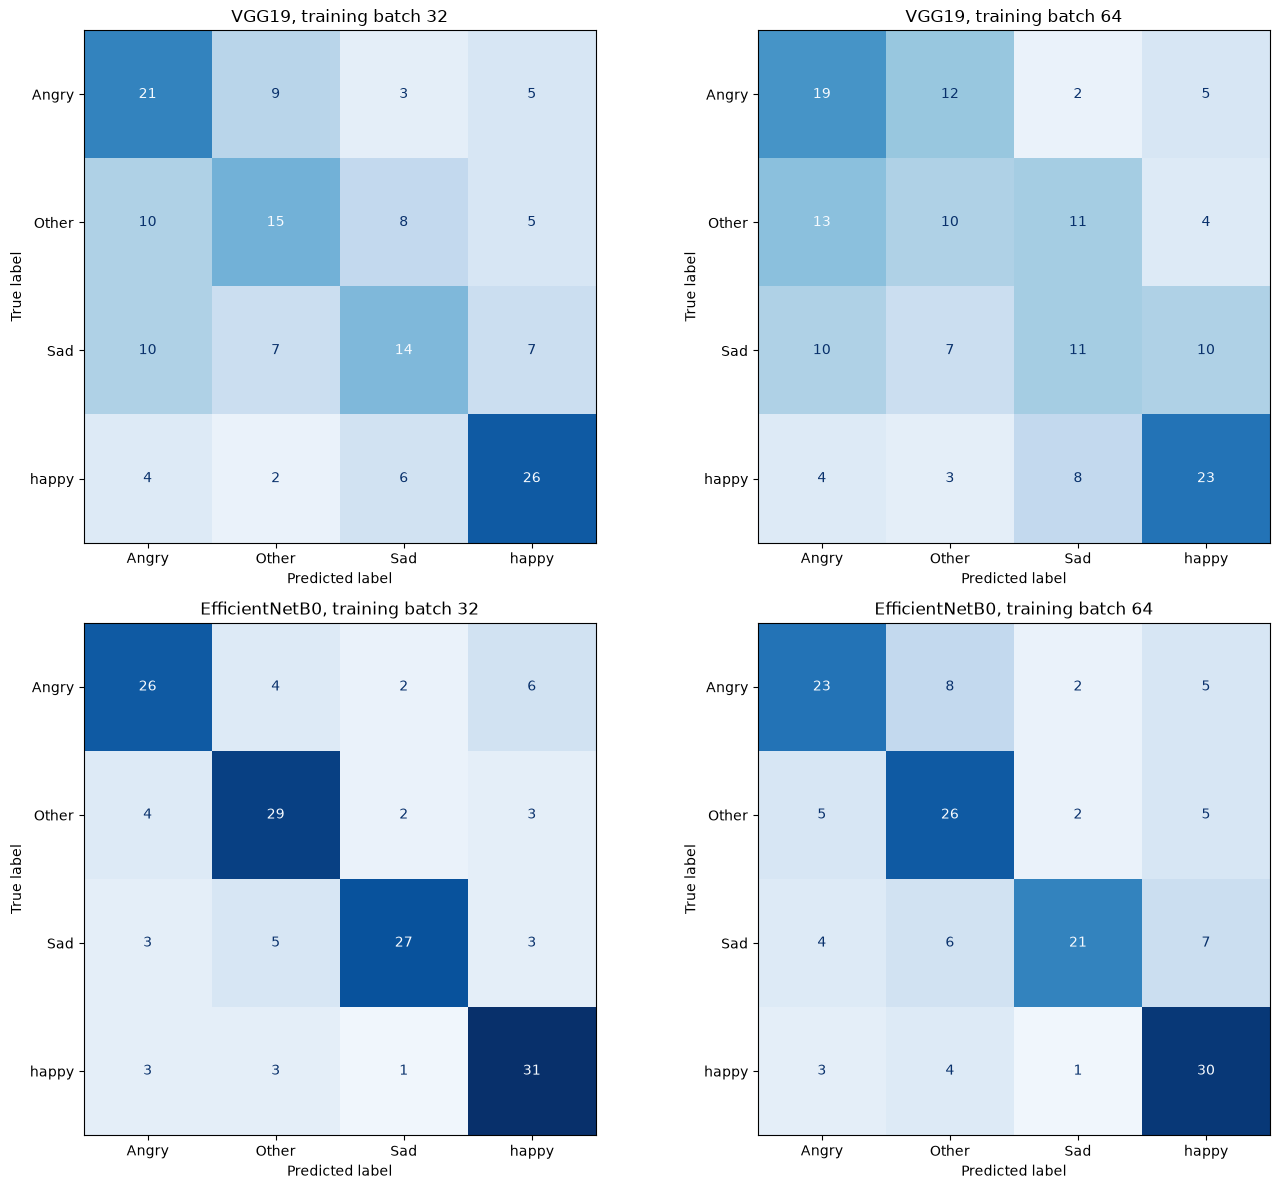

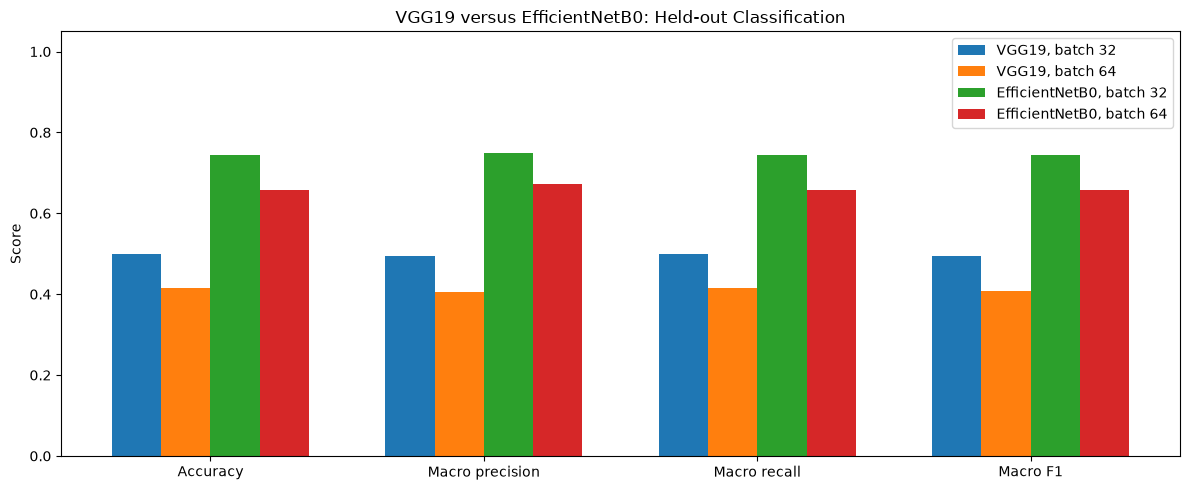

Batch 32, accuracy: EfficientNetB0 higher by 24.34 percentage points.
Batch 32, macro_f1: EfficientNetB0 higher by 24.94 percentage points.
Batch 64, accuracy: EfficientNetB0 higher by 24.34 percentage points.
Batch 64, macro_f1: EfficientNetB0 higher by 24.98 percentage points.
These are single-run comparisons; they do not establish statistical significance.


In [10]:
# Compare both architectures at each training batch size.
en_fig, en_axes = plt.subplots(2, len(en_batch_sizes), figsize=(14, 12), squeeze=False)
en_max_count = max(matrix.max() for matrix in en_confusion_matrices.values())
for row_index, en_name in enumerate(["VGG19", "EfficientNetB0"]):
    for col_index, en_batch in enumerate(en_batch_sizes):
        en_display = ConfusionMatrixDisplay(
            confusion_matrix=en_confusion_matrices[(en_name, en_batch)],
            display_labels=en_class_names,
        )
        en_display.plot(
            ax=en_axes[row_index, col_index], cmap=plt.cm.Blues,
            values_format="d", colorbar=False, im_kw={"vmin": 0, "vmax": en_max_count},
        )
        en_axes[row_index, col_index].set_title(f"{en_name}, training batch {en_batch}")
plt.tight_layout()
plt.show()

en_metrics = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]
en_x = np.arange(len(en_metrics))
en_width = 0.18
en_fig, en_ax = plt.subplots(figsize=(12, 5))
for index, row in enumerate(en_test_results):
    en_ax.bar(
        en_x + (index - (len(en_test_results) - 1) / 2) * en_width,
        [row[metric] for metric in en_metrics], en_width,
        label=f"{row['model']}, batch {row['training_batch_size']}",
    )
en_ax.set_xticks(en_x, ["Accuracy", "Macro precision", "Macro recall", "Macro F1"])
en_ax.set_ylim(0, 1.05)
en_ax.set_ylabel("Score")
en_ax.set_title("VGG19 versus EfficientNetB0: Held-out Classification")
en_ax.legend()
plt.tight_layout()
plt.show()

for en_batch in en_batch_sizes:
    en_pair = {row["model"]: row for row in en_test_results if row["training_batch_size"] == en_batch}
    for en_metric in ["accuracy", "macro_f1"]:
        en_delta = en_pair["EfficientNetB0"][en_metric] - en_pair["VGG19"][en_metric]
        if np.isclose(en_delta, 0):
            print(f"Batch {en_batch}, {en_metric}: tie.")
        else:
            en_winner = "EfficientNetB0" if en_delta > 0 else "VGG19"
            print(f"Batch {en_batch}, {en_metric}: {en_winner} higher by {abs(en_delta) * 100:.2f} percentage points.")
print("These are single-run comparisons; they do not establish statistical significance.")
